# 02 · Regressão — o que explica o quê?
Duas perguntas, duas regressões:
1. **Tempo de resposta → probabilidade de a conversa virar pedido** (logística, efeito de cada fator).
2. **Engajamento do post → conversas abertas em 48 h** (linear, com linha de tendência e análise de resíduos).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings; warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"font.size":10})
D="../data/core/"; ped=pd.read_csv(D+"fato_pedido.csv",parse_dates=["data_pedido"]); conv=pd.read_csv(D+"fato_conversa.csv",parse_dates=["iniciada_em"])
post=pd.read_csv(D+"fato_post_instagram.csv",parse_dates=["publicado_em"]); plat=pd.read_csv(D+"dim_plataforma.csv").set_index("plataforma_id"); loja=pd.read_csv(D+"dim_loja.csv",parse_dates=["data_adocao_atria"])
ped["canal"]=ped.plataforma_id.map(plat.nome); ped["mes"]=ped.data_pedido.dt.to_period("M")
import statsmodels.api as sm, statsmodels.formula.api as smf

## A. Engajamento do post → conversas em 48 h
Variável explicativa: salvamentos + compartilhamentos do post. Resposta: quantas conversas foram abertas nas 48 h seguintes.

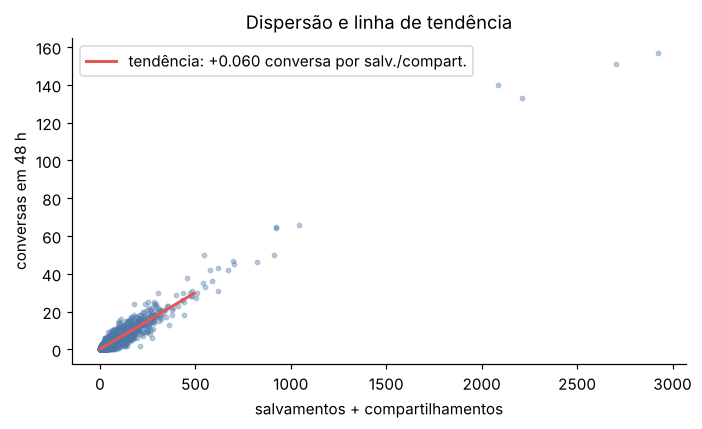

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1505      0.054      2.793      0.005       0.045       0.256
salv_comp      0.0598      0.000    177.618      0.000       0.059       0.060
R² = 0.939


In [2]:
post["salv_comp"]=post.salvamentos+post.compartilhamentos
fig,ax=plt.subplots(figsize=(6.5,4)); ax.scatter(post.salv_comp,post.conversas_48h_atribuidas,s=8,alpha=.35,color="#4C78A8")
m=smf.ols("conversas_48h_atribuidas ~ salv_comp",post).fit(); xs=np.linspace(0,post.salv_comp.quantile(.99),100); ax.plot(xs,m.params.Intercept+m.params.salv_comp*xs,c="#E45756",lw=2,label=f"tendência: +{m.params.salv_comp:.3f} conversa por salv./compart.")
ax.set_xlabel("salvamentos + compartilhamentos"); ax.set_ylabel("conversas em 48 h"); ax.legend(); ax.set_title("Dispersão e linha de tendência"); plt.tight_layout(); plt.savefig("../out/fig/reg_dispersao.png"); plt.show()
print(m.summary().tables[1]); print("R² =",round(m.rsquared,3))

**Leitura.** Cada salvamento ou compartilhamento extra está associado a ~0,06 conversa a mais (intervalo estreito: 0,059–0,060), e a reta explica cerca de 94% da variação (R² = 0,94). É um R² alto porque, na simulação, esse é o principal caminho do post até a conversa; em dados reais seria esperado menor. Agora olhamos os resíduos para ver se a reta é um bom resumo.

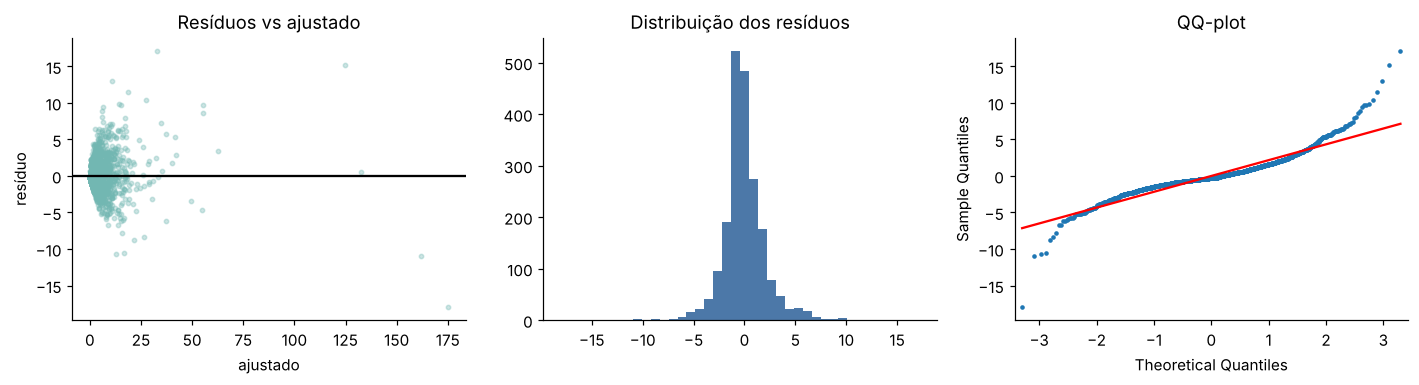

assimetria dos resíduos: 0.69


In [3]:
res=m.resid; fit=m.fittedvalues
fig,ax=plt.subplots(1,3,figsize=(13,3.6))
ax[0].scatter(fit,res,s=8,alpha=.35,color="#72B7B2"); ax[0].axhline(0,c="k"); ax[0].set_title("Resíduos vs ajustado"); ax[0].set_xlabel("ajustado"); ax[0].set_ylabel("resíduo")
ax[1].hist(res,bins=40,color="#4C78A8"); ax[1].set_title("Distribuição dos resíduos")
sm.qqplot(res,line="s",ax=ax[2],markersize=2); ax[2].set_title("QQ-plot"); plt.tight_layout(); plt.savefig("../out/fig/reg_residuos.png"); plt.show()
print("assimetria dos resíduos:",round(res.skew(),2))

**Leitura dos resíduos.** O gráfico à esquerda tem formato de leque: o erro cresce junto com o valor ajustado (heterocedasticidade). O histograma é concentrado em zero com caudas pesadas, e o QQ-plot em S confirma que os resíduos não são normais (assimetria 0,69). A variável resposta é uma contagem, e contagens têm variância que cresce com a média; posts virais criam as caudas. Isso não derruba a direção do efeito, mas os erros-padrão da reta linear não são confiáveis. Por isso, na regressão múltipla a seguir usamos erros-padrão robustos.

In [4]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
mm=smf.ols("conversas_48h_atribuidas ~ salv_comp + curtidas + comentarios",post).fit(cov_type="HC3"); print(mm.summary().tables[1]); print("R² =",round(mm.rsquared,3))
X=post[["salv_comp","curtidas","comentarios"]].assign(const=1.0); print("\nVIF (colinearidade):",{c:round(vif(X.values,i),1) for i,c in enumerate(["salv_comp","curtidas","comentarios"])})

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.0394      0.113      0.348      0.728      -0.183       0.262
salv_comp       0.0567      0.003     18.157      0.000       0.051       0.063
curtidas        0.0022      0.002      1.182      0.237      -0.001       0.006
comentarios    -0.0017      0.031     -0.057      0.955      -0.062       0.059
R² = 0.94

VIF (colinearidade): {'salv_comp': np.float64(3.5), 'curtidas': np.float64(16.6), 'comentarios': np.float64(13.2)}


**Leitura.** Usamos erros-padrão robustos (HC3) justamente por causa do leque nos resíduos. Com os três sinais no mesmo modelo, **só salvamentos+compartilhamentos mantêm efeito claro** (~0,057 conversa por unidade); curtidas e comentários perdem significância. Não é que curtida seja “inútil”: o VIF alto (>10) para curtidas e comentários mostra que eles andam juntos (correlação 0,96) e juntos acompanham o alcance do post, então o modelo não consegue separar o efeito de um do outro. Para o lojista, a leitura prática é: **salvamento e compartilhamento são o sinal mais confiável de conversa futura**; curtida sozinha diz pouco.

## B. Tempo de resposta → conversão (logística)
Cada conversa vira pedido ou não. Controlamos por intenção, canal, cliente recorrente e origem em post.

In [5]:
c=conv.dropna(subset=["tempo_primeira_resposta_min","converteu_7d"]).copy(); c["converteu_7d"]=c.converteu_7d.astype(int); c["log_resp"]=np.log1p(c.tempo_primeira_resposta_min/5)
c["origem_post"]=c.origem_post_id.notna().astype(int); c["noite"]=c.hora.between(17,22).astype(int)
ml=smf.logit("converteu_7d ~ log_resp + C(intencao) + C(canal) + cliente_recorrente + origem_post + noite + np.log1p(valor_historico)",c).fit(disp=0)
print(ml.summary().tables[1]); print("pseudo-R² (McFadden):",round(ml.prsquared,3))
print("\nOdds ratio de dobrar o tempo de resposta (+ln2 em log_resp ≈):", np.exp(ml.params["log_resp"]*np.log(2)).round(3))

                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                          0.3278      0.043      7.570      0.000       0.243       0.413
C(intencao)[T.duvida_produto]     -1.2466      0.028    -44.828      0.000      -1.301      -1.192
C(intencao)[T.pos_venda]          -3.9420      0.074    -53.392      0.000      -4.087      -3.797
C(intencao)[T.reclamacao]         -4.7944      0.146    -32.819      0.000      -5.081      -4.508
C(intencao)[T.troca_devolucao]    -4.6346      0.121    -38.196      0.000      -4.872      -4.397
C(canal)[T.whatsapp]               0.3915      0.028     13.888      0.000       0.336       0.447
log_resp                          -0.2893      0.010    -28.527      0.000      -0.309      -0.269
cliente_recorrente                -0.0262      0.117     -0.223      0.823      -0.256       0.204
origem_pos

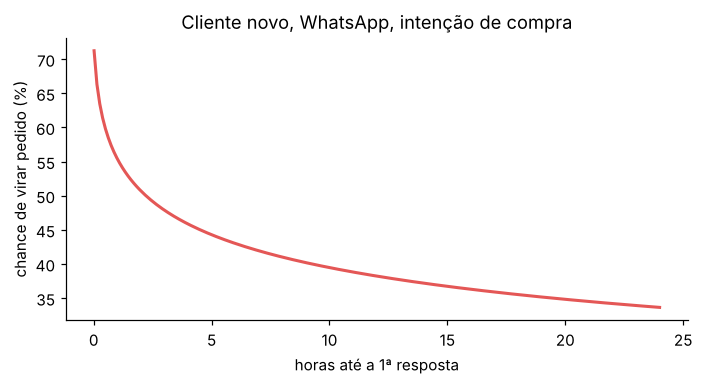

[0.712 0.494 0.406 0.336]


In [6]:
g=np.linspace(1,1440,200); base=c.iloc[:1].copy(); base=pd.concat([base]*len(g),ignore_index=True); base["tempo_primeira_resposta_min"]=g; base["log_resp"]=np.log1p(g/5)
for k,v in {"intencao":"compra","canal":"whatsapp","cliente_recorrente":0,"origem_post":0,"noite":1,"valor_historico":0}.items(): base[k]=v
pr=ml.predict(base); fig,ax=plt.subplots(figsize=(6.5,3.6)); ax.plot(g/60,pr*100,color="#E45756",lw=2); ax.set_xlabel("horas até a 1ª resposta"); ax.set_ylabel("chance de virar pedido (%)"); ax.set_title("Cliente novo, WhatsApp, intenção de compra"); plt.tight_layout(); plt.savefig("../out/fig/reg_logit_curva.png"); plt.show()
print(pr.iloc[[0,20,70,199]].round(3).values)

**Leitura.** O coeficiente de `log_resp` é negativo e muito significativo: dobrar o tempo de resposta multiplica as chances de virar pedido por ~0,82, mantidos os demais fatores. A curva mostra que a queda é mais forte logo nas primeiras horas (cerca de 71% no primeiro minuto, 49% em ~2,5 h, 34% em 24 h, para cliente novo no WhatsApp com intenção de compra), o que sugere uma regra simples: **responder em até 1 hora**. Origem em post (+0,51) e horário noturno (+0,24) ajudam; a intenção é o fator dominante (compra vs reclamação). O coeficiente de cliente recorrente deixa de ser significativo (p = 0,82) porque o valor histórico já carrega essa informação (as duas variáveis se correlacionam em 0,55).

## Limitações
- Dados simulados: os coeficientes refletem as relações que plantamos, com ruído; o objetivo é demonstrar o método e a leitura, não estimar o mundo real.
- Regressão mostra associação; a causalidade do tempo de resposta é sustentada aqui pelo desenho com loja de controle (EDA, seção 8).